In [26]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(r"C:\College Work\Project-1\data\raw")

file = DATA_DIR / "MDD S1 EC.edf"

raw = mne.io.read_raw_edf(
    file,
    preload=True,
    verbose=False
)

print(raw)

<RawEDF | MDD S1 EC.edf, 20 x 77568 (303.0 s), ~11.9 MiB, data loaded>


In [27]:
%matplotlib qt

In [28]:
eeg_channels = [
    "EEG Fp1-LE",
    "EEG F3-LE",
    "EEG C3-LE",
    "EEG P3-LE",
    "EEG O1-LE",
    "EEG F7-LE",
    "EEG T3-LE",
    "EEG T5-LE",
    "EEG Fz-LE",
    "EEG Fp2-LE",
    "EEG F4-LE",
    "EEG C4-LE",
    "EEG P4-LE",
    "EEG O2-LE",
    "EEG F8-LE",
    "EEG T4-LE",
    "EEG T6-LE",
    "EEG Cz-LE",
    "EEG Pz-LE",
]

raw.pick(eeg_channels)

print(raw)

<RawEDF | MDD S1 EC.edf, 19 x 77568 (303.0 s), ~11.3 MiB, data loaded>


In [29]:
raw.filter(
    l_freq=1.0,
    h_freq=45.0,
    verbose=False
)

raw.notch_filter(
    freqs=50,
    verbose=False
)

<RawEDF | MDD S1 EC.edf, 19 x 77568 (303.0 s), ~11.3 MiB, data loaded>

In [30]:
epochs = mne.make_fixed_length_epochs(
    raw,
    duration=10.0,
    overlap=0.0,
    preload=True,
    verbose=False
)

print(epochs)
print("Number of epochs:", len(epochs))

<Epochs | 30 events (all good), 0 – 9.996 s (baseline off), ~11.2 MiB, data loaded,
 '1': 30>
Number of epochs: 30


In [31]:
epochs.drop_bad(
    reject=dict(eeg=150e-6)
)

print("Remaining epochs:", len(epochs))

    Rejecting  epoch based on EEG : ['EEG C4-LE', 'EEG F8-LE', 'EEG T4-LE']
    Rejecting  epoch based on EEG : ['EEG F8-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F3-LE', 'EEG C3-LE', 'EEG P3-LE', 'EEG O1-LE', 'EEG F7-LE', 'EEG T3-LE', 'EEG T5-LE', 'EEG Fz-LE', 'EEG Fp2-LE', 'EEG F4-LE', 'EEG C4-LE', 'EEG P4-LE', 'EEG O2-LE', 'EEG F8-LE', 'EEG T4-LE', 'EEG T6-LE', 'EEG Cz-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG F8-LE']
    Rejecting  epoch based on EEG : ['EEG C4-LE', 'EEG P4-LE', 'EEG O2-LE', 'EEG F8-LE', 'EEG T4-LE', 'EEG T6-LE', 'EEG Cz-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG C4-LE', 'EEG P4-LE', 'EEG O2-LE', 'EEG F8-LE', 'EEG T4-LE', 'EEG T6-LE', 'EEG Cz-LE', 'EEG Pz-LE']
    Rejecting  epoch based on EEG : ['EEG Fp1-LE', 'EEG F3-LE', 'EEG C3-LE', 'EEG P3-LE', 'EEG O1-LE', 'EEG F7-LE', 'EEG T3-LE', 'EEG T5-LE', 'EEG Fz-LE', 'EEG Fp2-LE', 'EEG F4-LE', 'EEG C4-LE'

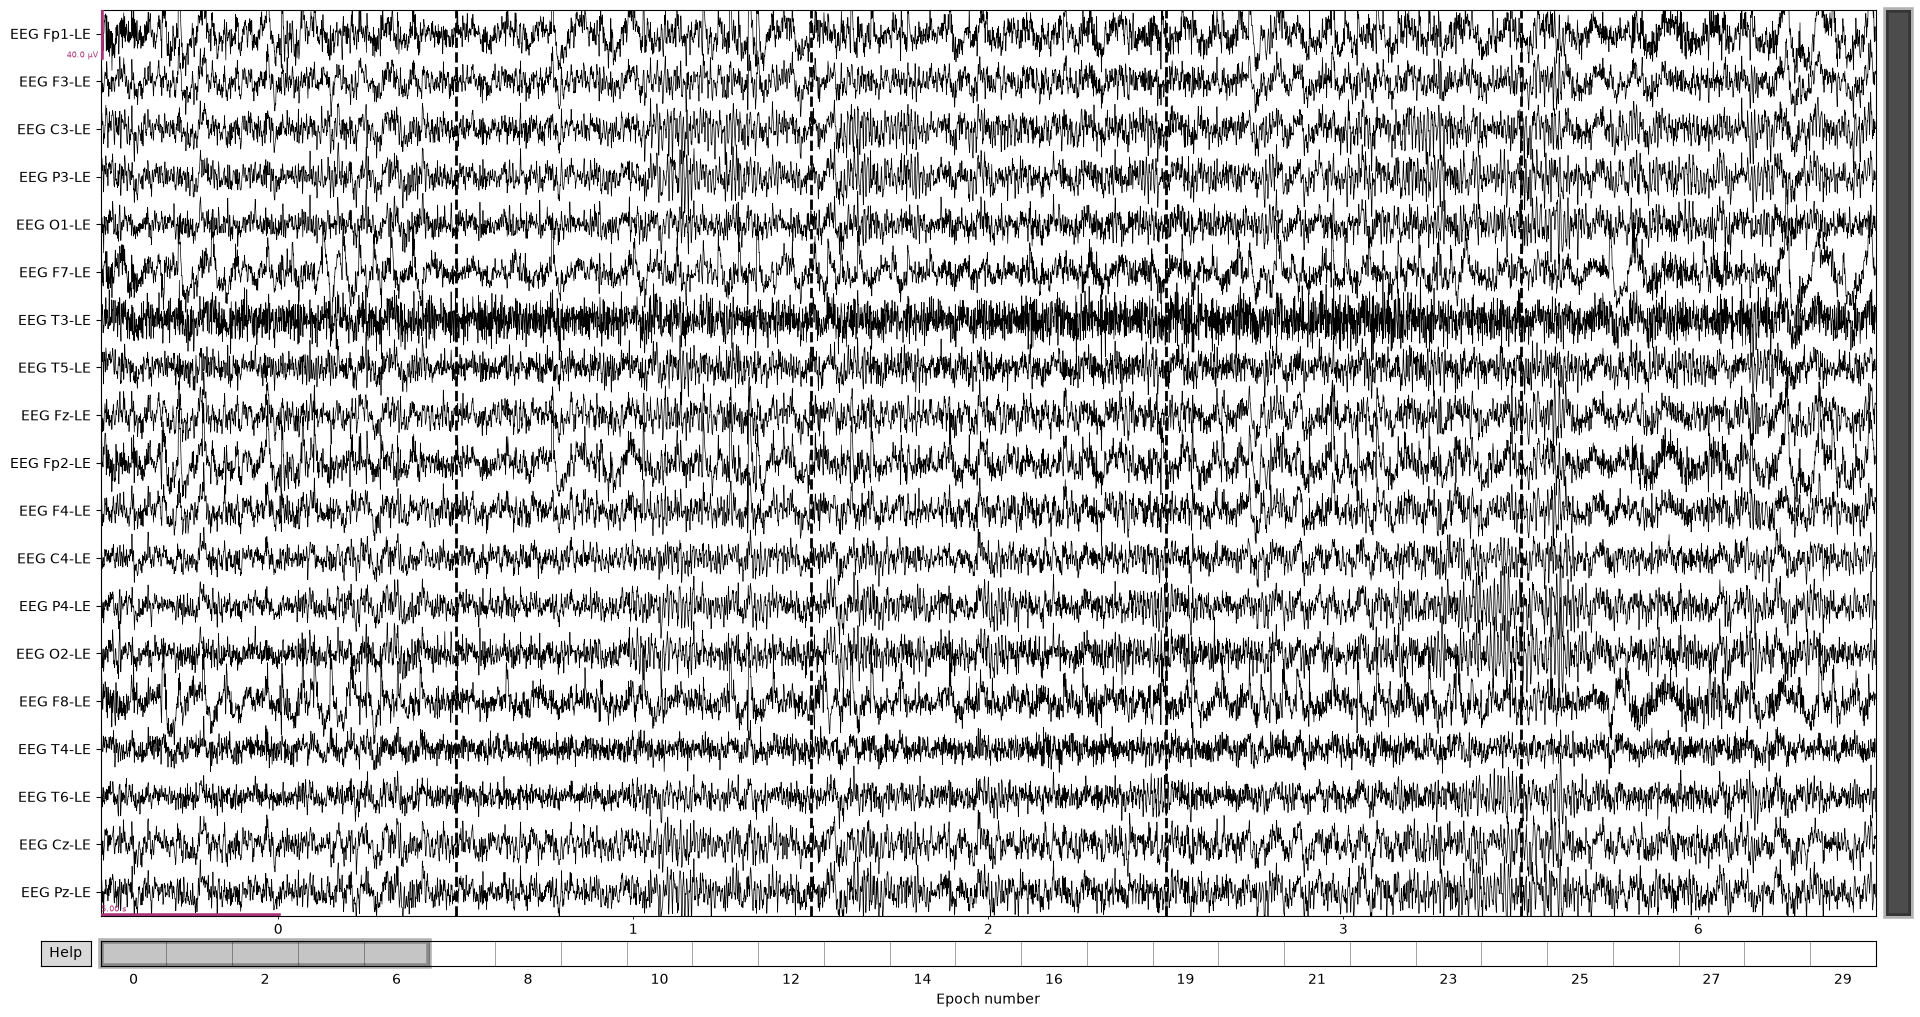

In [9]:
epochs.plot(
    n_epochs=5,
    n_channels=19
)

In [10]:
spectrum = epochs.compute_psd(
    method="welch",
    fmin=1,
    fmax=45,
    verbose=False
)

psds, freqs = spectrum.get_data(return_freqs=True)

print("PSD shape:", psds.shape)
print("Frequency shape:", freqs.shape)

PSD shape: (27, 19, 353)
Frequency shape: (353,)


In [13]:
plt.figure(figsize=(10, 5))

plt.plot(freqs, psds[0, 0])

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.title("EEG Power Spectral Density - H S1 EC")
plt.grid(True)

plt.show()

In [15]:
bands = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30),
    "gamma": (30, 45)
}

band_power = {}

for band_name, (low, high) in bands.items():
    mask = (freqs >= low) & (freqs < high)

    band_power[band_name] = np.trapezoid(
        psds[:, :, mask],
        freqs[mask],
        axis=2
    )

for band_name, values in band_power.items():
    print(band_name, values.shape)

delta (27, 19)
theta (27, 19)
alpha (27, 19)
beta (27, 19)
gamma (27, 19)


In [17]:
total_power = sum(band_power.values())

relative_band_power = {}

for band_name, values in band_power.items():
    relative_band_power[band_name] = values / total_power

for band_name, values in relative_band_power.items():
    print(band_name, values.shape)

relative_sum = sum(relative_band_power.values())

print(
    "Minimum sum:",
    relative_sum.min()
)

print(
    "Maximum sum:",
    relative_sum.max()
)

delta (27, 19)
theta (27, 19)
alpha (27, 19)
beta (27, 19)
gamma (27, 19)
Minimum sum: 0.9999999999999998
Maximum sum: 1.0000000000000002


In [18]:
recording_features = {}

for band_name, values in relative_band_power.items():
    recording_features[f"{band_name}_mean"] = values.mean(axis=0)
    recording_features[f"{band_name}_std"] = values.std(axis=0)

for feature_name, values in recording_features.items():
    print(feature_name, values.shape)

delta_mean (19,)
delta_std (19,)
theta_mean (19,)
theta_std (19,)
alpha_mean (19,)
alpha_std (19,)
beta_mean (19,)
beta_std (19,)
gamma_mean (19,)
gamma_std (19,)


In [20]:
feature_dict = {}

for band_name, values in relative_band_power.items():
    for channel_idx, channel_name in enumerate(epochs.ch_names):

        clean_channel = channel_name.replace("EEG ", "").replace("-LE", "")

        feature_dict[
            f"{clean_channel}_{band_name}_mean"
        ] = values[:, channel_idx].mean()

        feature_dict[
            f"{clean_channel}_{band_name}_std"
        ] = values[:, channel_idx].std()

feature_df = pd.DataFrame([feature_dict])

print("Feature shape:", feature_df.shape)
print(feature_df.head())

Feature shape: (1, 190)
   Fp1_delta_mean  Fp1_delta_std  F3_delta_mean  F3_delta_std  C3_delta_mean  \
0        0.397628       0.148343       0.293056      0.088013       0.180975   

   C3_delta_std  P3_delta_mean  P3_delta_std  O1_delta_mean  O1_delta_std  \
0      0.069786       0.156205      0.072968       0.160176      0.066007   

   ...  F8_gamma_mean  F8_gamma_std  T4_gamma_mean  T4_gamma_std  \
0  ...       0.067049      0.031078       0.100022      0.060441   

   T6_gamma_mean  T6_gamma_std  Cz_gamma_mean  Cz_gamma_std  Pz_gamma_mean  \
0        0.06966      0.039983       0.035588      0.016232       0.040178   

   Pz_gamma_std  
0      0.024339  

[1 rows x 190 columns]


In [21]:
feature_df.insert(0, "condition", "EC")
feature_df.insert(0, "group", "Healthy")
feature_df.insert(0, "subject_id", "H_S1")

print(feature_df.shape)
print(feature_df.iloc[:, :8])

(1, 193)
  subject_id    group condition  Fp1_delta_mean  Fp1_delta_std  F3_delta_mean  \
0       H_S1  Healthy        EC        0.397628       0.148343       0.293056   

   F3_delta_std  C3_delta_mean  
0      0.088013       0.180975  
